<a href="https://colab.research.google.com/github/santhwana27/Machine-Learning-Lab-Programs/blob/main/Naive_Bayes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving Naive_Bayes_Dataset.xlsx to Naive_Bayes_Dataset (1).xlsx

TASK 1: LOAD AND UNDERSTAND THE DATASET

First 10 Records:
 Study_Hours_Per_Day  Attendance_Percent  Assignment_Score_Percent  Previous_Marks_Percent Study_Level Attendance_Level Assignment_Level Result
                   1                  92                        67                      87         Low             High           Medium   Pass
                   7                  85                        79                      47        High             High           Medium   Pass
                   6                  70                        78                      65        High           Medium           Medium   Fail
                   4                  94                        69                      75      Medium             High           Medium   Pass
                   4                  71                        88                      65      Medium           Medium             High   Pass
            

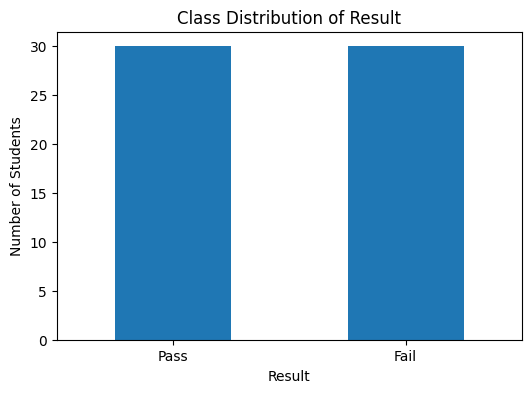


Numerical Features:
['Study_Hours_Per_Day', 'Attendance_Percent', 'Assignment_Score_Percent', 'Previous_Marks_Percent']

Categorical Features:
['Study_Level', 'Attendance_Level', 'Assignment_Level']

TASK 2: BAYES THEOREM AND PROBABILITY CALCULATION

Prior Probabilities:
Pass: 0.5000
Fail: 0.5000

Selected Categorical Features:
['Study_Level', 'Attendance_Level']

Conditional Probability Table:
         Feature  Value   Pass   Fail
     Study_Level    Low 0.1000 0.5000
     Study_Level   High 0.6000 0.3000
     Study_Level Medium 0.3000 0.2000
Attendance_Level   High 0.3667 0.2333
Attendance_Level Medium 0.4333 0.3333
Attendance_Level    Low 0.2000 0.4333

Naive Bayes Assumption:
The selected features are assumed to be conditionally independent given the class.

New Student for Manual Calculation:
{'Study_Level': 'High', 'Attendance_Level': 'Medium'}

Prior × Conditional Probabilities:
Pass: 0.130000
Fail: 0.050000

Normalized Posterior Probabilities:
Pass: 0.7222
Fail: 0.2778

Predic

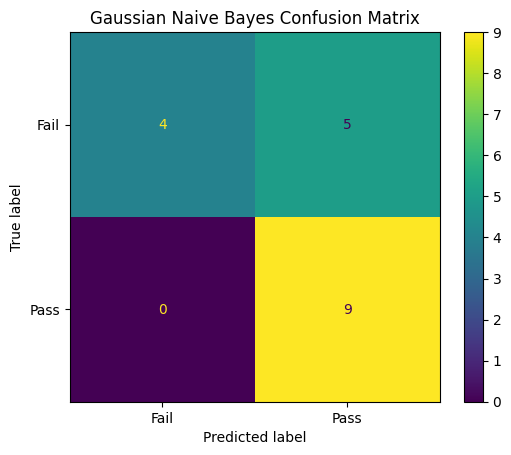


True Positive (TP): 9
True Negative (TN): 4
False Positive (FP): 5
False Negative (FN): 0

TASK 5: CATEGORICAL NAIVE BAYES

GaussianNB vs CategoricalNB:
   Metric  GaussianNB  CategoricalNB
 Accuracy      0.7222         0.6111
Precision      0.6429         0.5714
   Recall      1.0000         0.8889
 F1-score      0.7826         0.6957

Reason for Difference:
GaussianNB works with numerical features and assumes a Gaussian distribution, while CategoricalNB works with categorical features and calculates probabilities for category values.

TASK 6: NEW PREDICTION

New Student Records:
Study_Level Attendance_Level Assignment_Level
       High           Medium           Medium
        Low             High           Medium
     Medium              Low              Low

Predictions and Class Probabilities:
Study_Level Attendance_Level Assignment_Level Predicted Result  P(Fail)  P(Pass)
       High           Medium           Medium             Pass   0.2539   0.7461
        Low             Hig

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from sklearn.naive_bayes import GaussianNB, CategoricalNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# TASK 1: LOAD AND UNDERSTAND THE DATASET

uploaded = files.upload()
file_name = list(uploaded.keys())[0]

df = pd.read_excel(file_name)

target = "Result"

print("\n" + "=" * 60)
print("TASK 1: LOAD AND UNDERSTAND THE DATASET")
print("=" * 60)

print("\nFirst 10 Records:")
print(df.head(10).to_string(index=False))

features = [col for col in df.columns if col != target]

print("\nInput Features:")
print(features)

print("\nTarget Variable:")
print(target)

print("\nClass Distribution:")
print(df[target].value_counts().to_string())

plt.figure(figsize=(6, 4))
df[target].value_counts().plot(kind="bar")
plt.xlabel("Result")
plt.ylabel("Number of Students")
plt.title("Class Distribution of Result")
plt.xticks(rotation=0)
plt.show()

numerical_features = df[features].select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = df[features].select_dtypes(
    exclude=np.number
).columns.tolist()

print("\nNumerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)


# TASK 2: BAYES THEOREM AND PROBABILITY CALCULATION

print("\n" + "=" * 60)
print("TASK 2: BAYES THEOREM AND PROBABILITY CALCULATION")
print("=" * 60)

classes = df[target].dropna().unique()

priors = df[target].value_counts(normalize=True)

print("\nPrior Probabilities:")
for c in classes:
    print(f"{c}: {priors[c]:.4f}")

selected_features = categorical_features[:2]

print("\nSelected Categorical Features:")
print(selected_features)

probability_rows = []

for feature in selected_features:

    values = df[feature].dropna().unique()

    for value in values:

        row = {
            "Feature": feature,
            "Value": value
        }

        for c in classes:

            subset = df[df[target] == c]

            count = (
                subset[feature] == value
            ).sum()

            probability = count / len(subset)

            row[c] = probability

        probability_rows.append(row)

probability_table = pd.DataFrame(probability_rows)

print("\nConditional Probability Table:")
print(
    probability_table.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\nNaive Bayes Assumption:")
print(
    "The selected features are assumed to be conditionally "
    "independent given the class."
)

new_record = {}

for feature in selected_features:
    new_record[feature] = df[feature].mode()[0]

print("\nNew Student for Manual Calculation:")
print(new_record)

likelihoods = {}

for c in classes:

    value_product = 1

    for feature in selected_features:

        value = new_record[feature]

        subset = df[df[target] == c]

        count = (
            subset[feature] == value
        ).sum()

        total = len(subset)

        probability = count / total

        value_product *= probability

    likelihoods[c] = priors[c] * value_product

print("\nPrior × Conditional Probabilities:")
for c in classes:
    print(f"{c}: {likelihoods[c]:.6f}")

total_probability = sum(likelihoods.values())

if total_probability > 0:

    posterior = {
        c: likelihoods[c] / total_probability
        for c in classes
    }

else:

    posterior = {
        c: 0
        for c in classes
    }

print("\nNormalized Posterior Probabilities:")
for c in classes:
    print(f"{c}: {posterior[c]:.4f}")

prediction = max(posterior, key=posterior.get)

print("\nPredicted Class:", prediction)


# TASK 3: LAPLACE SMOOTHING AND COMPLETE NAIVE BAYES WORKING

print("\n" + "=" * 60)
print("TASK 3: LAPLACE SMOOTHING AND COMPLETE NAIVE BAYES WORKING")
print("=" * 60)

print("\nLaplace Smoothing Formula:")
print("P = (count + 1) / (total + number of possible values)")

laplace_rows = []

for feature in selected_features:

    values = df[feature].dropna().unique()

    k = len(values)

    for value in values:

        row = {
            "Feature": feature,
            "Value": value
        }

        for c in classes:

            subset = df[df[target] == c]

            count = (
                subset[feature] == value
            ).sum()

            total = len(subset)

            probability = (count + 1) / (total + k)

            row[c] = probability

        laplace_rows.append(row)

laplace_table = pd.DataFrame(laplace_rows)

print("\nLaplace-Smoothed Probability Table:")
print(
    laplace_table.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\nManual Naive Bayes Steps:")
print(
    "Prior → Conditional Probabilities → Likelihood "
    "→ Posterior → Normalized Posterior → Prediction"
)

print("\nZero Probability Situation:")
print(
    "If a selected feature value does not occur in a class, "
    "its conditional probability becomes zero."
)

print(
    "Laplace smoothing prevents zero probability "
    "by adding one to the count."
)


# TASK 4: IMPLEMENT NAIVE BAYES USING SCIKIT-LEARN

print("\n" + "=" * 60)
print("TASK 4: IMPLEMENT NAIVE BAYES USING SCIKIT-LEARN")
print("=" * 60)

X_num = df[numerical_features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X_num,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

gaussian_model = GaussianNB()

gaussian_model.fit(
    X_train,
    y_train
)

gaussian_pred = gaussian_model.predict(X_test)

gaussian_accuracy = accuracy_score(
    y_test,
    gaussian_pred
)

gaussian_precision = precision_score(
    y_test,
    gaussian_pred,
    pos_label="Pass",
    zero_division=0
)

gaussian_recall = recall_score(
    y_test,
    gaussian_pred,
    pos_label="Pass",
    zero_division=0
)

gaussian_f1 = f1_score(
    y_test,
    gaussian_pred,
    pos_label="Pass",
    zero_division=0
)

gaussian_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score"
    ],
    "Value": [
        gaussian_accuracy,
        gaussian_precision,
        gaussian_recall,
        gaussian_f1
    ]
})

print("\nGaussian Naive Bayes Results:")
print(
    gaussian_results.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

cm = confusion_matrix(
    y_test,
    gaussian_pred,
    labels=gaussian_model.classes_
)

print("\nConfusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=gaussian_model.classes_
)

disp.plot()
plt.title("Gaussian Naive Bayes Confusion Matrix")
plt.show()

tn, fp, fn, tp = cm.ravel()

print("\nTrue Positive (TP):", tp)
print("True Negative (TN):", tn)
print("False Positive (FP):", fp)
print("False Negative (FN):", fn)


# TASK 5: CATEGORICAL NAIVE BAYES

print("\n" + "=" * 60)
print("TASK 5: CATEGORICAL NAIVE BAYES")
print("=" * 60)

X_cat = df[categorical_features].astype(str)

encoder = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

X_cat_encoded = encoder.fit_transform(X_cat)

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_cat_encoded,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

categorical_model = CategoricalNB()

categorical_model.fit(
    Xc_train,
    yc_train
)

categorical_pred = categorical_model.predict(
    Xc_test
)

categorical_accuracy = accuracy_score(
    yc_test,
    categorical_pred
)

categorical_precision = precision_score(
    yc_test,
    categorical_pred,
    pos_label="Pass",
    zero_division=0
)

categorical_recall = recall_score(
    yc_test,
    categorical_pred,
    pos_label="Pass",
    zero_division=0
)

categorical_f1 = f1_score(
    yc_test,
    categorical_pred,
    pos_label="Pass",
    zero_division=0
)

comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score"
    ],
    "GaussianNB": [
        gaussian_accuracy,
        gaussian_precision,
        gaussian_recall,
        gaussian_f1
    ],
    "CategoricalNB": [
        categorical_accuracy,
        categorical_precision,
        categorical_recall,
        categorical_f1
    ]
})

print("\nGaussianNB vs CategoricalNB:")
print(
    comparison.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\nReason for Difference:")
print(
    "GaussianNB works with numerical features and assumes "
    "a Gaussian distribution, while CategoricalNB works "
    "with categorical features and calculates probabilities "
    "for category values."
)


# TASK 6: NEW PREDICTION

print("\n" + "=" * 60)
print("TASK 6: NEW PREDICTION")
print("=" * 60)

new_students = pd.DataFrame()

for feature in categorical_features:

    values = df[feature].dropna().unique()

    new_students[feature] = [
        df[feature].mode()[0],
        values[0],
        values[-1]
    ]

new_students = new_students[categorical_features]

new_students_encoded = encoder.transform(
    new_students.astype(str)
)

new_predictions = categorical_model.predict(
    new_students_encoded
)

new_probabilities = categorical_model.predict_proba(
    new_students_encoded
)

print("\nNew Student Records:")
print(
    new_students.to_string(
        index=False
    )
)

prediction_table = new_students.copy()

prediction_table["Predicted Result"] = new_predictions

for i, c in enumerate(categorical_model.classes_):

    prediction_table[f"P({c})"] = (
        new_probabilities[:, i]
    )

print("\nPredictions and Class Probabilities:")

print(
    prediction_table.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print(
    "\nThe class with the higher predicted probability "
    "is selected as the final classification."
)